# Ejercicios de Regresión lineal

Carga de librerías

In [2]:
import numpy as np
from scipy import stats
import statsmodels.api as sm
import matplotlib.pyplot as plt

def regresion_lineal(x, y):
  return stats.linregress(x, y) # pendiente, ordenada, r, p, error estándar

**1. Problema: Temperatura y tiempo de vida del dispositivo**

In [13]:
temperatura_1 = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90])
tiempo_vida = np.array([420, 365, 285, 220, 176, 117, 69, 34, 5])
r1 = regresion_lineal(temperatura_1, tiempo_vida)
n = len(temperatura_1)
print("Ecuación de la recta:\n", "y = ", r1.slope, "t +", r1.intercept)
print("\nCoeficiente de determinación R^2: ", r1.rvalue**2)

# Valor crítico de t Student
t_critico = stats.t.ppf(0.975, n-2)

print("\nIntervalo de confianza del 95% de la pendiente:")
print("IC =", r1.slope - t_critico*r1.stderr,",", r1.slope + t_critico*r1.stderr)


Ecuación de la recta:
 y =  -5.3133333333333335 t + 453.55555555555554

Coeficiente de determinación R^2:  0.9840369938137091

Intervalo de confianza del 95% de la pendiente:
IC = -5.918161224239989 , -4.708505442426678


**2. Problema: Rendimiento de un proceso químico**

In [15]:
temperatura_2 = np.array([0, 25, 50, 75, 100])
rendimiento = np.array([14, 38, 54, 76, 95])
r2 = regresion_lineal(temperatura_2, rendimiento)
print("Ecuación de la recta:\n", "y = ", r2.slope, "x +", r2.intercept)
print("\nCoeficiente de determinación R^2: ", r2.rvalue**2)

print("\nEstimación a 105°C:")
print(r2.intercept + r2.slope*105, "g")


Ecuación de la recta:
 y =  0.8 x + 15.399999999999999

Coeficiente de determinación R^2:  0.9972078181092939

Estimación a 105°C:
99.4 g


**3. Problema: Tiempo de enfriamiento y resistencia al impacto**

In [21]:
tiempo_enfriamiento = np.array([15, 25, 35, 40])
fuerza_impacto = np.array([42.1, 36.0, 31.8, 28.7])

r3 = regresion_lineal(tiempo_enfriamiento, fuerza_impacto)
print("Ecuación de la recta:\n", "y = ", r3.slope, "x +", r3.intercept)
print("\nCoeficiente de determinación R^2: ", r3.rvalue**2)

print("\nMedidas de tendencia central:")
for v in (tiempo_enfriamiento, fuerza_impacto):
  print("Media: ", v.mean(), "Mediana: ", np.median(v), stats.mode(v, keepdims=False))

Ecuación de la recta:
 y =  -0.5213559322033899 x + 49.63898305084746

Coeficiente de determinación R^2:  0.9938589783450839

Medidas de tendencia central:
Media:  28.75 Mediana:  30.0 ModeResult(mode=np.int64(15), count=np.int64(1))
Media:  34.65 Mediana:  33.9 ModeResult(mode=np.float64(28.7), count=np.int64(1))


**4. Problema: Contaminación en una corriente de agua**

In [22]:
distancia = np.array([2, 4, 6, 8, 10])
concentracion = np.array([11.5, 10.2, 10.3, 9.68, 9.32])

r4 = regresion_lineal(distancia, concentracion)
print("Ecuación de la recta:\n", "y = ", r4.slope, "x +", r4.intercept)
print("\nCoeficiente de determinación R^2: ", r4.rvalue**2)

print("\nMedidas de tendencia central:")
for i in (distancia, concentracion):
  print("Media: ", i.mean(), "Mediana: ", np.median(i), stats.mode(i, keepdims=False))

print("\nEstimación de concentración a 12km:")
print(r4.intercept + r4.slope*12)

Ecuación de la recta:
 y =  -0.24399999999999997 x + 11.664

Coeficiente de determinación R^2:  0.8676187700378897

Medidas de tendencia central:
Media:  6.0 Mediana:  6.0 ModeResult(mode=np.int64(2), count=np.int64(1))
Media:  10.2 Mediana:  10.2 ModeResult(mode=np.float64(9.32), count=np.int64(1))

Estimación de concentración a 12km:
8.736


**5. Problema: Filtración por membrana**

In [28]:
presion = np.array([1.02, 2.08, 2.89, 4.01, 5.32, 5.83, 7.26, 7.96, 9.11, 9.99])
flujo = np.array([1.15, 0.85, 1.56, 1.72, 4.32, 5.07, 5.00, 5.31, 6.17, 7.04])

r5 = regresion_lineal(presion, flujo)

print("\nCorrelación empírica:", r5.rvalue)

print("\nEcuación de la recta:\n", "y = ", r5.slope, "x +", r5.intercept)
print("\nCoeficiente de determinación R^2: ", r5.rvalue**2)
print("\nValor P: ", r5.pvalue)


Correlación empírica: 0.9638184397950357

Ecuación de la recta:
 y =  0.7224760000677398 x + -0.18857437237575247

Coeficiente de determinación R^2:  0.9289459848889368

Valor P:  7.177034203000306e-06


**6. Problema: Challenger regresión logística**

In [32]:
temperatura_lanzamientos = [53,56,57,63,66,67,67,67,68,69,70,70,70,70,72,73,75,75,76,76,78,79,80,81]
incidencia_falla = [1,1,1,0,0,0,0,0,0,0,0,1,1,1,0,0,0,1,0,0,0,0,0,0]

X = sm.add_constant(np.array(temperatura_lanzamientos, float))
m1 = sm.Logit(np.array(incidencia_falla), X).fit()

print(m1.summary())
print(np.exp(m1.params), np.exp(m1.conf_int()))

Optimization terminated successfully.
         Current function value: 0.479801
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   24
Model:                          Logit   Df Residuals:                       22
Method:                           MLE   Df Model:                            1
Date:                Fri, 16 Oct 2026   Pseudo R-squ.:                  0.2052
Time:                        02:30:08   Log-Likelihood:                -11.515
converged:                       True   LL-Null:                       -14.487
Covariance Type:            nonrobust   LLR p-value:                   0.01477
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         10.8753      5.703      1.907      0.057      -0.303      22.053
x1            -0.1713      0.

**7. Problema: Experiencia y éxito del consultor**

In [33]:
exito   = [8,13,14,18,20,21,21,22,25,26,28,29,30,32]
fracaso = [4,5,6,6,7,9,10,11,11,13,15,18,19,20,23,27]

xs = np.array(exito + fracaso, float)
ys = np.array([1]*len(exito) + [0]*len(fracaso))
m2 = sm.Logit(ys, sm.add_constant(xs)).fit()

print(m2.summary())
print(np.exp(m2.params), np.exp(m2.conf_int()))

Optimization terminated successfully.
         Current function value: 0.513319
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   30
Model:                          Logit   Df Residuals:                       28
Method:                           MLE   Df Model:                            1
Date:                Fri, 16 Oct 2026   Pseudo R-squ.:                  0.2571
Time:                        02:30:45   Log-Likelihood:                -15.400
converged:                       True   LL-Null:                       -20.728
Covariance Type:            nonrobust   LLR p-value:                  0.001097
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -3.2111      1.235     -2.599      0.009      -5.632      -0.790
x1             0.1777      0.

Gráfica de la probabilidad estimada

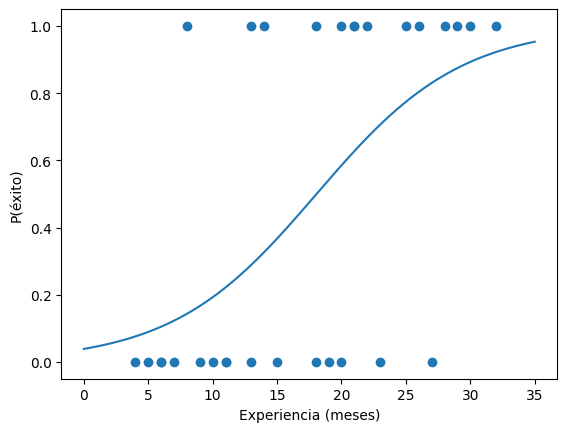

In [35]:
tt = np.linspace(0, 35, 200)
b0, b1 = m2.params

plt.scatter(xs, ys)
plt.plot(tt, 1/(1+np.exp(-(b0+b1*tt))))
plt.xlabel('Experiencia (meses)')
plt.ylabel('P(éxito)'); plt.show()

**9. Problema: Caso de aplicación diagnóstico de diabetes**

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score
import numpy as np

# Usamos la variable objetivo 'incidencia_falla' correspondiente a las características 'X'
y = np.array(incidencia_falla)

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=1)
modelo = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
print(classification_report(yte, modelo.predict(Xte)))
print(roc_auc_score(yte, modelo.predict_proba(Xte)[:,1]))

              precision    recall  f1-score   support

           0       0.71      0.83      0.77         6
           1       0.00      0.00      0.00         2

    accuracy                           0.62         8
   macro avg       0.36      0.42      0.38         8
weighted avg       0.54      0.62      0.58         8

0.45833333333333337


**10. Problema: Abandono de clientes en telecomunicaciones**

In [40]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

df = pd.DataFrame({
    'churn': [0, 0, 1, 0, 1, 1, 0, 0, 1, 0,
              1, 0, 1, 0, 0, 1, 0, 1, 0, 1,
              0, 1, 0, 1, 0, 0, 1, 0, 1, 0],

    'antiguedad': [24, 36, 3, 18, 2, 5, 30, 42, 4, 20,
                   6, 28, 1, 15, 48, 7, 32, 3, 22, 8,
                   40, 4, 26, 6, 35, 19, 2, 29, 5, 45],

    'contrato': ['Anual', 'Anual', 'Mensual', 'Anual', 'Mensual',
                 'Mensual', 'Anual', 'Anual', 'Mensual', 'Anual',
                 'Mensual', 'Anual', 'Mensual', 'Anual', 'Anual',
                 'Mensual', 'Anual', 'Mensual', 'Anual', 'Mensual',
                 'Anual', 'Mensual', 'Anual', 'Mensual', 'Anual',
                 'Anual', 'Mensual', 'Anual', 'Mensual', 'Anual'],

    'cargo_mensual': [50, 65, 90, 55, 95, 85, 45, 60, 100, 55,
                      80, 50, 105, 60, 40, 95, 55, 110, 65, 90,
                      45, 100, 50, 85, 60, 70, 105, 55, 95, 45],

    'llamadas_soporte': [1, 2, 5, 1, 6, 4, 0, 1, 7, 2,
                         5, 1, 8, 2, 0, 6, 1, 7, 2, 5,
                         0, 6, 1, 4, 2, 3, 7, 1, 5, 0]
})

print(df.head())

   churn  antiguedad contrato  cargo_mensual  llamadas_soporte
0      0          24    Anual             50                 1
1      0          36    Anual             65                 2
2      1           3  Mensual             90                 5
3      0          18    Anual             55                 1
4      1           2  Mensual             95                 6


In [41]:
import statsmodels.formula.api as smf
m10 = smf.logit('churn ~ antiguedad + C(contrato) + cargo_mensual + llamadas_soporte', data=df).fit()
print(m10.summary()); print(np.exp(m10.params))

         Current function value: 0.000000
         Iterations: 35
                           Logit Regression Results                           
Dep. Variable:                  churn   No. Observations:                   30
Model:                          Logit   Df Residuals:                       25
Method:                           MLE   Df Model:                            4
Date:                Fri, 16 Oct 2026   Pseudo R-squ.:                   1.000
Time:                        03:43:36   Log-Likelihood:            -9.9827e-12
converged:                      False   LL-Null:                       -20.527
Covariance Type:            nonrobust   LLR p-value:                 2.620e-08
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                -19.0805   5.95e+06  -3.21e-06      1.000   -1.17e+07    1.17e+07
C(contrato)[T.Mensual]    41.

/usr/local/lib/python3.13/dist-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/usr/local/lib/python3.13/dist-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/usr/local/lib/python3.13/dist-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/usr/local/lib/python3.13/dist-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/usr/local/lib/python3.13/dist-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/usr/local